# Experiment 9: unified stratified 5-fold cross-validation

This notebook evaluates the selected image-only Experiment 9 CNN with one shuffled stratified 5-fold split (`random_state=271828`). The architecture has three convolution/pooling blocks followed by a 64-to-64 convolution and ReLU, a 64-unit hidden layer and dropout 0.5. The additional convolution has no extra pooling; the model has 392,338 trainable parameters.

Each fold resets Python, NumPy and PyTorch training seeds to 42 and creates a fresh model and AdamW optimizer (learning rate 0.001, weight decay 1e-4). Training uses horizontal/vertical flips, batch size 32, at most 40 epochs and early stopping with patience 6. Channel mean and standard deviation are fitted on each training fold only. The validation fold is never augmented.

The official [Kaggle competition overview](https://www.kaggle.com/c/statoil-iceberg-classifier-challenge) specifies log loss. Accuracy uses threshold 0.5 and is a secondary metric. Each validation fold selects its best epoch and is then scored, which can make scores optimistic. The model architecture was previously selected using the whole labeled dataset, so these results are exploratory cross-validation scores and do not constitute an independent final generalization estimate. Fixed seeds do not guarantee identical results across GPU runs.

The filename contains a historical label retained to preserve the existing path; this version runs the single 5-fold procedure described here. No Kaggle submission is made. Review the implementation and disclose actual Codex assistance in accordance with the course AI policy.


In [ ]:
import copy
import hashlib
import platform
import random
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import sklearn
import torch
import torch.nn as nn
from sklearn.metrics import accuracy_score, log_loss
from sklearn.model_selection import StratifiedKFold
from torch.utils.data import DataLoader, Dataset, TensorDataset

TRAINING_SEED = 42
SPLIT_SEED = 271828
train_path = Path("data/train.json")
with train_path.open("rb") as stream:
    train_sha256 = hashlib.file_digest(stream, "sha256").hexdigest()
train = pd.read_json(train_path)
band1 = np.stack(train["band_1"]).reshape(-1, 75, 75)
band2 = np.stack(train["band_2"]).reshape(-1, 75, 75)
X = np.stack([band1, band2], axis=1).astype(np.float32)
y = train["is_iceberg"].to_numpy(dtype=np.int64)
ids = train["id"].to_numpy()
assert len(np.unique(ids)) == len(ids)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Data:", X.shape, "| class counts:", np.bincount(y).tolist())
print("train.json SHA-256:", train_sha256)
print("Split seed:", SPLIT_SEED, "| training seed:", TRAINING_SEED)
print("Python:", sys.version.split()[0], "| torch:", torch.__version__, "| CUDA build:", torch.version.cuda)
print("NumPy:", np.__version__, "| pandas:", pd.__version__, "| scikit-learn:", sklearn.__version__)
print("OS:", platform.platform(), "| device:", device)
if device.type == "cuda": print("GPU:", torch.cuda.get_device_name(0))


Data: (1604, 2, 75, 75) | class counts: [851, 753]
train.json SHA-256: a56756a2528a09b139dc2747e2e40d869f9da7a8c9df37b188b6163f6bfb8696
Split seed: 271828 | training seed: 42
Python: 3.13.1 | torch: 2.8.0+cu128 | CUDA build: 12.8
NumPy: 2.2.1 | pandas: 2.2.3 | scikit-learn: 1.9.0
OS: Windows-11-10.0.26300-SP0 | device: cuda
GPU: NVIDIA GeForce RTX 4090 Laptop GPU


In [ ]:
class AugmentedImages(Dataset):
    def __init__(self, images, labels):
        self.images = torch.from_numpy(images).float()
        self.labels = torch.from_numpy(labels).long()

    def __len__(self):
        return len(self.images)

    def __getitem__(self, index):
        image = self.images[index].clone()
        if torch.rand(1).item() < 0.5:
            image = torch.flip(image, dims=[2])
        if torch.rand(1).item() < 0.5:
            image = torch.flip(image, dims=[1])
        return image, self.labels[index]


class Experiment9CNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(2, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(64, 64, 3, padding=1), nn.ReLU(),
        )
        self.classifier = nn.Sequential(nn.Flatten(), nn.Linear(64 * 9 * 9, 64),
                                        nn.ReLU(), nn.Dropout(0.5), nn.Linear(64, 2))

    def forward(self, images):
        return self.classifier(self.features(images))


model_check = Experiment9CNN()
assert sum(p.numel() for p in model_check.parameters()) == 392338
print("Trainable parameters:", sum(p.numel() for p in model_check.parameters() if p.requires_grad))


Trainable parameters: 392338


In [ ]:
def run_fold(train_idx, val_idx):
    random.seed(TRAINING_SEED)
    np.random.seed(TRAINING_SEED)
    torch.manual_seed(TRAINING_SEED)
    X_tr, X_va = X[train_idx].copy(), X[val_idx].copy()
    y_tr, y_va = y[train_idx], y[val_idx]
    mean = X_tr.mean(axis=(0, 2, 3), keepdims=True)
    std = X_tr.std(axis=(0, 2, 3), keepdims=True)
    X_tr = (X_tr - mean) / (std + 1e-8)
    X_va = (X_va - mean) / (std + 1e-8)
    training = AugmentedImages(X_tr, y_tr)
    validation = TensorDataset(torch.from_numpy(X_va), torch.from_numpy(y_va))
    train_loader = DataLoader(training, batch_size=32, shuffle=True)
    val_loader = DataLoader(validation, batch_size=32, shuffle=False)
    model = Experiment9CNN().to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=0.001, weight_decay=1e-4)
    criterion = nn.CrossEntropyLoss()
    best_loss, best_epoch, best_state, wait = float("inf"), 0, None, 0
    train_losses, val_losses = [], []
    for epoch in range(40):
        model.train()
        train_loss_sum = 0.0
        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()
            loss = criterion(model(images), labels)
            loss.backward()
            optimizer.step()
            train_loss_sum += loss.item() * len(labels)
        train_losses.append(train_loss_sum / len(training))
        model.eval()
        val_loss_sum = 0.0
        with torch.no_grad():
            for images, labels in val_loader:
                images, labels = images.to(device), labels.to(device)
                val_loss_sum += criterion(model(images), labels).item() * len(labels)
        val_loss = val_loss_sum / len(validation)
        val_losses.append(val_loss)
        if val_loss < best_loss:
            best_loss, best_epoch = val_loss, epoch + 1
            best_state = copy.deepcopy(model.state_dict())
            wait = 0
        else:
            wait += 1
        if wait >= 6:
            break
    model.load_state_dict(best_state)
    model.eval()
    probabilities = []
    with torch.no_grad():
        for images, _ in val_loader:
            probabilities.extend(torch.softmax(model(images.to(device)), dim=1)[:, 1].cpu().numpy())
    probabilities = np.asarray(probabilities, dtype=np.float32)
    return {"best_epoch": best_epoch,
            "log_loss": log_loss(y_va, probabilities, labels=[0, 1]),
            "accuracy": accuracy_score(y_va, probabilities >= 0.5),
            "train_losses": train_losses, "val_losses": val_losses}, probabilities


## Run the unified 5-fold evaluation


In [ ]:
splitter = StratifiedKFold(n_splits=5, shuffle=True, random_state=SPLIT_SEED)
oof_probabilities = np.full(len(y), np.nan, dtype=np.float32)
fold_assignment = np.zeros(len(y), dtype=np.int64)
fold_results = []
fold_histories = {}
for fold, (train_idx, val_idx) in enumerate(splitter.split(X, y), 1):
    assert not np.intersect1d(train_idx, val_idx).size
    assert np.isnan(oof_probabilities[val_idx]).all()
    result, probabilities = run_fold(train_idx, val_idx)
    assert np.isfinite(probabilities).all() and np.all((probabilities >= 0) & (probabilities <= 1))
    oof_probabilities[val_idx] = probabilities
    fold_assignment[val_idx] = fold
    fold_histories[fold] = result
    fold_results.append({"fold": fold, "train_size": len(train_idx), "validation_size": len(val_idx),
                         "best_epoch": result["best_epoch"], "log_loss": result["log_loss"],
                         "accuracy": result["accuracy"]})
    print(f"Fold {fold}: best epoch {result['best_epoch']} | "
          f"log loss {result['log_loss']:.6f} | accuracy {result['accuracy']:.2%}", flush=True)
assert np.isfinite(oof_probabilities).all() and np.all(fold_assignment > 0)
results_df = pd.DataFrame(fold_results)
print("\nFold results:")
print(results_df.to_string(index=False))
print(f"Mean fold log loss: {results_df.log_loss.mean():.6f}")
print(f"Pooled OOF log loss: {log_loss(y, oof_probabilities, labels=[0, 1]):.6f}")
print(f"Pooled OOF accuracy: {accuracy_score(y, oof_probabilities >= 0.5):.4%}")


Fold 1: best epoch 17 | log loss 0.265853 | accuracy 90.03%
Fold 2: best epoch 23 | log loss 0.220147 | accuracy 90.34%
Fold 3: best epoch 31 | log loss 0.219180 | accuracy 90.34%
Fold 4: best epoch 17 | log loss 0.272558 | accuracy 88.79%
Fold 5: best epoch 25 | log loss 0.209335 | accuracy 91.25%

Fold results:
 fold  train_size  validation_size  best_epoch  log_loss  accuracy
    1        1283              321          17  0.265853  0.900312
    2        1283              321          23  0.220147  0.903427
    3        1283              321          31  0.219180  0.903427
    4        1283              321          17  0.272558  0.887850
    5        1284              320          25  0.209335  0.912500
Mean fold log loss: 0.237415
Pooled OOF log loss: 0.237432
Pooled OOF accuracy: 90.1496%


## Recorded GPU results

| Fold | Training size | Validation size | Best epoch | Log loss | Accuracy |
| --- | ---: | ---: | ---: | ---: | ---: |
| 1 | 1283 | 321 | 17 | 0.2659 | 90.03% |
| 2 | 1283 | 321 | 23 | 0.2201 | 90.34% |
| 3 | 1283 | 321 | 31 | 0.2192 | 90.34% |
| 4 | 1283 | 321 | 17 | 0.2726 | 88.79% |
| 5 | 1284 | 320 | 25 | 0.2093 | 91.25% |

Mean fold log loss: **0.2374**. Pooled OOF log loss: **0.2374**. Pooled OOF accuracy: **90.15%**. The score uses each row once; fold 5 has one fewer validation sample, so the pooled metric differs slightly from the unweighted fold mean.

The same validation fold selects the best epoch and is reported. The architecture was previously chosen using all labeled data. These scores are exploratory; they do not establish independent generalization, a Kaggle leaderboard score, or the course's Top-5-level target. The 05/06 experiments and historical OOF files remain separate.


## Training and validation loss by fold

The saved figure uses the measured GPU histories; running the cell can redraw it without training.


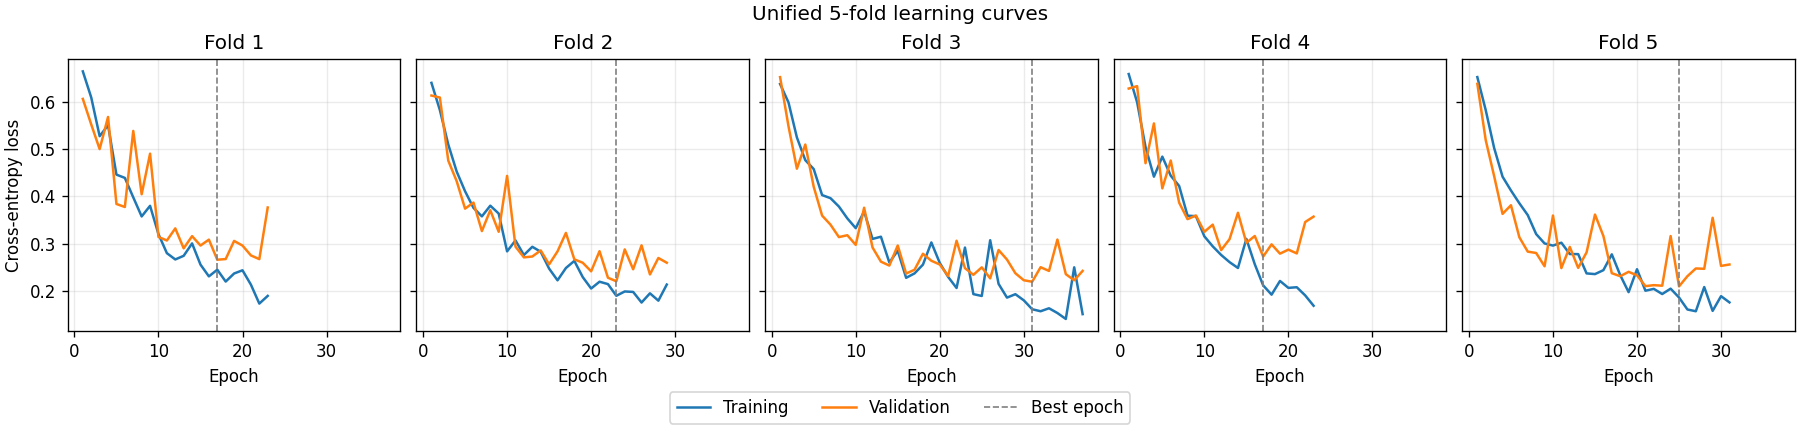

In [ ]:
import matplotlib.pyplot as plt

# Full-precision histories from the recorded GPU run.
_recorded_fold_histories = {1: {'best_epoch': 17, 'log_loss': 0.2658528983592987, 'accuracy': 0.9003115264797508, 'train_losses': [0.6649356684643871, 0.6096030441189035, 0.5276258193415213, 0.5507950957687404, 0.4461344324882757, 0.43922650656101764, 0.3980223857510954, 0.3575472636605647, 0.3800371119568149, 0.3200867880754237, 0.27973356007199823, 0.2663831776087858, 0.27410691622891464, 0.3003890265500868, 0.2554826070021022, 0.2305343996988216, 0.24463389654783932, 0.21954886528169004, 0.23662852436095036, 0.24343246286001785, 0.21299053931395384, 0.17287235745952545, 0.18916957692438424], 'val_losses': [0.6066220319159678, 0.5524450752222649, 0.5001942298122656, 0.5683256885344365, 0.38392791458379444, 0.3775601244047052, 0.538762997986743, 0.4045416352533477, 0.4905759659233123, 0.31419975438221964, 0.3064998189608256, 0.33222322170608143, 0.2899678706008697, 0.3157610408613615, 0.29590318006147104, 0.3083499771226604, 0.26585291293551244, 0.2672273674486582, 0.3056649126553461, 0.2957886520575883, 0.2749440829701884, 0.26707749816116144, 0.37648583052685697]}, 2: {'best_epoch': 23, 'log_loss': 0.2201470136642456, 'accuracy': 0.9034267912772586, 'train_losses': [0.6406399123573898, 0.582978924107756, 0.5100419549206134, 0.4527275094229638, 0.41090948404693456, 0.37567031592572003, 0.3576656878226824, 0.3803497554668293, 0.36367080974177, 0.28353578182095585, 0.3067503484751411, 0.27575502893651543, 0.2932089838959329, 0.28273960816167987, 0.2470076502658665, 0.2221795631077544, 0.24824695374500166, 0.2633501715458703, 0.22905839836792563, 0.20481643431645036, 0.21920656756187962, 0.21417640505245336, 0.18939616308719592, 0.19857152004959244, 0.1975667054822272, 0.17510877656391063, 0.19461632712757967, 0.17907155248962942, 0.21317295845821557], 'val_losses': [0.6137397404400359, 0.6095219428282568, 0.47584048376601434, 0.4323412415243662, 0.3740915769357176, 0.3869039472946868, 0.32651630881593513, 0.3707160989785091, 0.3250963200939779, 0.44345233744867507, 0.2935517354160431, 0.2707934484489239, 0.27263539946548104, 0.28545838838147225, 0.2559523158880804, 0.2834609883213256, 0.32264611454110453, 0.2665879753334129, 0.25943335600058054, 0.24123976004202605, 0.2839279371354369, 0.22769152443867607, 0.22014697409319078, 0.28764559323292893, 0.2455729221159192, 0.2963220991775962, 0.23465068966753758, 0.2695016573462309, 0.2594437353962864]}, 3: {'best_epoch': 31, 'log_loss': 0.2191796898841858, 'accuracy': 0.9034267912772586, 'train_losses': [0.6381323495509563, 0.5992389045371177, 0.5249665859427567, 0.4767870973281719, 0.4580044203778309, 0.4028260627832621, 0.396220627698876, 0.3785232483574123, 0.3534325106782274, 0.33274755599623257, 0.3680629860304894, 0.3098746636419304, 0.3145735190059069, 0.2599183982724523, 0.2848388387060152, 0.22745785809652655, 0.23687019481941396, 0.2554401004874232, 0.3024348306004321, 0.25903076445357187, 0.22933945670579906, 0.2059019845115516, 0.29156527932463266, 0.19292932595485648, 0.18898397052278765, 0.3071342706738369, 0.21460980924887296, 0.1855445750760363, 0.19277399212749136, 0.17974095587747133, 0.16088102745155014, 0.15664065555492976, 0.16294848855036084, 0.15286934264265553, 0.14030263903358442, 0.24970284725712874, 0.15050917881848008], 'val_losses': [0.6527219708092116, 0.5487222749496175, 0.4587318637289362, 0.509854913871979, 0.4205191274669683, 0.35936836912253195, 0.340066393216451, 0.3137632359596799, 0.31773357785008033, 0.29730642733172835, 0.3759572233923499, 0.2917721431203349, 0.26172245124418786, 0.2533955837707282, 0.2959555188814799, 0.23652080731971242, 0.24458192367791387, 0.27843482212114185, 0.2636425408804528, 0.2556903013187777, 0.23133433979248333, 0.305973611145376, 0.24793997007738391, 0.23380530381871162, 0.24968433640084906, 0.22629082592848304, 0.2863894338455527, 0.26616701641558116, 0.2371338244724868, 0.22230683884516683, 0.21917969582608185, 0.24997421885576576, 0.2420780016718624, 0.30851467891459894, 0.23525175888590352, 0.2222313750941434, 0.24210853203899022]}, 4: {'best_epoch': 17, 'log_loss': 0.2725578844547272, 'accuracy': 0.8878504672897196, 'train_losses': [0.659287292002145, 0.5995351316077767, 0.5049212528849986, 0.4417873793343316, 0.4842740332857297, 0.44390233196695617, 0.4222258337289211, 0.35911025986110245, 0.35813695944944396, 0.3154175573239859, 0.2941464713294805, 0.2759433161047747, 0.2607112952035475, 0.24832808506832585, 0.31002300345888384, 0.2563117701249576, 0.211395493426178, 0.19178984998866905, 0.22084593191011195, 0.206164226272751, 0.2075287943962883, 0.19019990980578697, 0.1682736340277239], 'val_losses': [0.6285768459519122, 0.6336248255221644, 0.4703707539960974, 0.5546471509978036, 0.41705931439949345, 0.47594207246726916, 0.3868450082351114, 0.35180866430481644, 0.35956736628511615, 0.3249964946213634, 0.34014858698872763, 0.28619971339854866, 0.3094499803313585, 0.3653767004469845, 0.30170202905143906, 0.3160518837390566, 0.27255787070248727, 0.2983679091151676, 0.27872563056891486, 0.287190625026265, 0.2792009301773763, 0.34572818912304587, 0.35719076204447314]}, 5: {'best_epoch': 25, 'log_loss': 0.20933537185192108, 'accuracy': 0.9125, 'train_losses': [0.652824546689185, 0.5827134442849322, 0.502643036136746, 0.4418327128775766, 0.4125912834736417, 0.3855078118241093, 0.36036493547980286, 0.3201931770716872, 0.30034789823668767, 0.2957646230299525, 0.30187141691041514, 0.27786596876067166, 0.2776655132339751, 0.23682172628949363, 0.2353565759747942, 0.24369899023359068, 0.2772244211878175, 0.2333112192743478, 0.1971146971730057, 0.2456938419200921, 0.20014520279622153, 0.20404522550347437, 0.19311974817347305, 0.2044828998569016, 0.18578564404652126, 0.1603561496808893, 0.1566376854140439, 0.20792807671139915, 0.1574194046822478, 0.188600411899736, 0.1753886439532877], 'val_losses': [0.6385107636451721, 0.5190466225147248, 0.44295439720153806, 0.3629554659128189, 0.3812775731086731, 0.3133695602416992, 0.2829723209142685, 0.2801090583205223, 0.25193230509757997, 0.35947770774364474, 0.24812516272068025, 0.2929803729057312, 0.24853940308094025, 0.2814226746559143, 0.36154275089502336, 0.31608816236257553, 0.2372757911682129, 0.23092256337404252, 0.24013062715530395, 0.23282719701528548, 0.2098534032702446, 0.211890809237957, 0.21077702045440674, 0.3159391194581985, 0.20933535546064377, 0.2309240072965622, 0.24731404185295106, 0.24657991379499436, 0.35468426495790484, 0.2527249537408352, 0.2557010181248188]}}
histories_to_plot = fold_histories if "fold_histories" in globals() else _recorded_fold_histories
fig, axes = plt.subplots(1, 5, figsize=(15, 3.6), sharex=True, sharey=True, constrained_layout=True)
for fold, ax in enumerate(axes, 1):
    r = histories_to_plot[fold]
    epochs = range(1, len(r["train_losses"]) + 1)
    ax.plot(epochs, r["train_losses"], color="tab:blue", label="Training")
    ax.plot(epochs, r["val_losses"], color="tab:orange", label="Validation")
    ax.axvline(r["best_epoch"], color="gray", linestyle="--", linewidth=1, label="Best epoch")
    ax.set_title(f"Fold {fold}")
    ax.set_xlabel("Epoch")
    ax.grid(alpha=0.25)
axes[0].set_ylabel("Cross-entropy loss")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside lower center", ncol=3)
fig.suptitle("Unified 5-fold learning curves")
plt.show()


## Recheck saved OOF predictions

The CSV contains the previously recorded predictions. Run the next cell to check its SHA-256 and reproduce pooled metrics.


In [1]:
# Recheck the saved OOF predictions without retraining.
import hashlib
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, log_loss

expected_oof_sha256 = "fe959a5e1219ba164f45b86abd42f6cf17c7da06fb41f639a6a3e996f48d1ee3"
with open("experiment9_unified5fold_oof.csv", "rb") as stream:
    actual_sha256 = hashlib.file_digest(stream, "sha256").hexdigest()
if actual_sha256 != expected_oof_sha256:
    raise ValueError("OOF file differs from the recorded run; inspect it before use.")
oof = pd.read_csv("experiment9_unified5fold_oof.csv", dtype={"id": "string"})
assert len(oof) == 1604 and oof["id"].is_unique and set(oof["fold"]) == set(range(1, 6))
probs = oof.predicted_iceberg_probability.to_numpy(dtype=np.float32)
print("Pooled OOF log loss:", f"{log_loss(oof.is_iceberg, probs, labels=[0, 1]):.6f}")
print("Pooled OOF accuracy:", f"{accuracy_score(oof.is_iceberg, probs >= 0.5):.4%}")


Pooled OOF log loss: 0.237432
Pooled OOF accuracy: 90.1496%
